# FEEDBACK PRIZE: Evaluating Student Writing
## Token Classification & Discourse Argumentation Pipeline (DeBERTa-v3)
### Google Colab (Tesla T4 GPU) & Local Environment Ready

---

### Problem Overview
This notebook implements an end-to-end Deep Learning NLP pipeline to automatically identify and classify argumentative elements (**Discourse Elements**) in student essays, using the official **Kaggle Feedback Prize - Evaluating Student Writing** dataset (`train.csv` and `train/*.txt`).

Each continuous segment (**Span**) of an essay is categorized into one of **7 discourse classes**:
1. **`Lead`** — An introduction that grabs the reader's attention and provides background
2. **`Position`** — The author's main stance, thesis, or opinion on the topic
3. **`Claim`** — A claim that supports the author's main position
4. **`Counterclaim`** — A claim that refutes, opposes, or raises doubts about the position
5. **`Rebuttal`** — A claim that refutes or counters a counterclaim
6. **`Evidence`** — Factual evidence, examples, statistics, or reasoning used to support a claim
7. **`Concluding Statement`** — A concluding statement that restates claims or summarizes the essay

---

### Pipeline Architecture
```
 ┌────────────────────────────────────────────────────────┐
 │   1. Raw Kaggle Data (train.csv + train/*.txt)         │
 └──────────────────────────┬─────────────────────────────┘
                            ▼
 ┌────────────────────────────────────────────────────────┐
 │   2. Word-Level BIO Tagging (15 Labels)                │
 │      [O, B-Lead, I-Lead, B-Claim, I-Claim, ...]        │
 └──────────────────────────┬─────────────────────────────┘
                            ▼
 ┌────────────────────────────────────────────────────────┐
 │   3. Subword Token Alignment & Loss Masking (-100)     │
 │      DeBERTa-v3 Fast Tokenizer                         │
 └──────────────────────────┬─────────────────────────────┘
                            ▼
 ┌────────────────────────────────────────────────────────┐
 │   4. Transformer Deep Learning (DeBERTa-v3 Base)       │
 │      PyTorch AMP FP16 + GradScaler + AdamW + Scheduler │
 └──────────────────────────┬─────────────────────────────┘
                            ▼
 ┌────────────────────────────────────────────────────────┐
 │   5. Span-Level Post-Processing & Official Macro-F1    │
 │      IoU >= 0.5 Overlap Evaluation Metric              │
 └──────────────────────────┬─────────────────────────────┘
                            ▼
 ┌────────────────────────────────────────────────────────┐
 │   6. Interactive HTML Visualizer & Error Analysis      │
 │      Ground Truth vs Prediction Color Highlighting     │
 └────────────────────────────────────────────────────────┘
```

## 1. Package Installation & Compute Environment Verification

In [ ]:
# Install required dependencies for Google Colab / cloud environment
%pip install -q transformers sentencepiece protobuf datasets accelerate matplotlib seaborn

In [ ]:
import os
import gc
import re
import random
import yaml
from pathlib import Path
from typing import List, Dict, Tuple, Any, Optional

# Disable Hugging Face Hub xet-protocol to prevent SentencePiece stalls in Colab
os.environ['HUGGINGFACE_HUB_DISABLE_XET'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import LambdaLR
from sklearn.model_selection import train_test_split
from IPython.display import HTML, display

# Hugging Face Transformers models and tokenizers
from transformers import AutoTokenizer, AutoConfig, AutoModelForTokenClassification

# Native PyTorch Linear Warmup Scheduler
def get_linear_schedule_with_warmup(optimizer, num_warmup_steps: int, num_training_steps: int, last_epoch: int = -1):
    def lr_lambda(current_step: int):
        if current_step < num_warmup_steps:
            return float(current_step) / float(max(1, num_warmup_steps))
        return max(0.0, float(num_training_steps - current_step) / float(max(1, num_training_steps - num_warmup_steps)))
    return LambdaLR(optimizer, lr_lambda, last_epoch)

# Fix random seed for full experiment reproducibility
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(42)

# Check compute hardware device (GPU / CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f" Computations are running on device: {device}")
if torch.cuda.is_available():
    print(f"   GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"   Available VRAM: {round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2)} GB")
else:
    print("ℹ CUDA is not available, running on CPU.")

⚡ Computations are running on device: cuda
   🚀 GPU Model: Tesla T4
   💾 Available VRAM: 15.64 GB


## 2. Configuration & Universal Dataset Path Discovery

The helper function below dynamically searches for `train.csv` and the `train/` text directory across common Colab, local workspace, and cloud storage directory structures.

In [ ]:
def find_kaggle_dataset_paths() -> Tuple[Path, Path]:
    """
    Automatically discovers the location of train.csv and the train/ text folder
    across various environments (Colab / Local / Drive).
    """
    csv_candidates = [
        Path("data/train.csv"),
        Path("train.csv"),
        Path("/content/data/train.csv"),
        Path("/content/train.csv"),
        Path("feedback-prize-2021/train.csv"),
        Path("/content/feedback-prize-2021/train.csv"),
        Path("../data/train.csv")
    ]

    txt_dir_candidates = [
        Path("data/train"),
        Path("train"),
        Path("/content/data/train"),
        Path("/content/train"),
        Path("feedback-prize-2021/train"),
        Path("/content/feedback-prize-2021/train"),
        Path("../data/train")
    ]

    found_csv = None
    for p in csv_candidates:
        if p.exists() and p.is_file():
            found_csv = p.resolve()
            break

    found_txt_dir = None
    for p in txt_dir_candidates:
        if p.exists() and p.is_dir() and len(os.listdir(p)) > 0:
            found_txt_dir = p.resolve()
            break

    if found_csv is None or found_txt_dir is None:
        raise FileNotFoundError(
            "❌ Unable to find `train.csv` or `train/` directory.\n"
            "Please ensure the Kaggle dataset is unzipped in data/ or /content/data/."
        )

    return found_csv, found_txt_dir

CSV_PATH, TXT_DIR = find_kaggle_dataset_paths()
print(f"✅ Found train.csv file      : {CSV_PATH}")
print(f"✅ Found train/ text folder  : {TXT_DIR}")

# Hyperparameter Configuration Dictionary
CFG = {
    "model_name": "microsoft/deberta-v3-base",
    "max_len": 1024,
    "num_labels": 15,
    "dropout": 0.1,
    "seed": 42,
    "epochs": 2,
    "batch_size": 2,
    "gradient_accumulation_steps": 8,
    "learning_rate": 2.0e-5,
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "max_grad_norm": 1.0,
    "o_class_weight": 0.40,
    "o_threshold": 0.50,
    "max_train_essays": None,            # Set to an integer (e.g. 500) for rapid testing
    "output_dir": "outputs/"
}

os.makedirs(CFG["output_dir"], exist_ok=True)

# 7 Target Discourse Element Categories
DISCOURSE_TYPES = [
    "Lead",
    "Position",
    "Claim",
    "Counterclaim",
    "Rebuttal",
    "Evidence",
    "Concluding Statement"
]

# BIO (Beginning, Inside, Outside) Tagging Scheme -> 15 Output Labels
LABELS = ["O"]
for dt in DISCOURSE_TYPES:
    LABELS.append(f"B-{dt}")
    LABELS.append(f"I-{dt}")

LABEL2ID = {lbl: i for i, lbl in enumerate(LABELS)}
ID2LABEL = {i: lbl for i, lbl in enumerate(LABELS)}
NUM_LABELS = len(LABELS)

print(f"🏷️ Total BIO labels count: {NUM_LABELS}")

✅ Found train.csv file      : /content/data/train.csv
✅ Found train/ text folder  : /content/data/train
🏷️ Total BIO labels count: 15


## 3. Word-Level BIO Tagging & Subword Alignment (Data Preprocessing)

> 🔍 **Mechanism**:
> 1. The raw essay text is split into whitespace-delimited words (`words = text.split()`).
> 2. Using `predictionstring` word indices from `train.csv`, each word is labeled with `B-{type}`, `I-{type}`, or `O`.
> 3. Hugging Face Fast Tokenizer tokenizes words into SentencePiece subwords. The first subword receives the ground truth BIO tag, while subsequent subwords and special tokens (`[CLS]`, `[SEP]`, `[PAD]`) are assigned **`-100`** so that PyTorch `CrossEntropyLoss(ignore_index=-100)` ignores them during loss computation.

In [ ]:
def get_essay_text(essay_id: str, txt_dir: Path) -> str:
    path = os.path.join(str(txt_dir), f"{essay_id}.txt")
    with open(path, "r", encoding="utf-8") as f:
        return f.read()

def build_word_labels(essay_id: str, text: str, grouped_df: dict) -> Tuple[List[str], List[str]]:
    words = text.split()
    word_labels = ["O"] * len(words)

    if essay_id in grouped_df:
        essay_rows = grouped_df[essay_id]
        for _, row in essay_rows.iterrows():
            dtype = row["discourse_type"]
            w_indices = [int(x) for x in str(row["predictionstring"]).split()]
            if not w_indices:
                continue

            if w_indices[0] < len(word_labels):
                word_labels[w_indices[0]] = f"B-{dtype}"

            for idx in w_indices[1:]:
                if idx < len(word_labels):
                    word_labels[idx] = f"I-{dtype}"

    return words, word_labels

# Demonstration test on the first essay in the dataset
grouped_df = dict(tuple(df.groupby('id')))
sample_id = df['id'].iloc[0]
sample_text = get_essay_text(sample_id, TXT_DIR)
words, w_labels = build_word_labels(sample_id, sample_text, grouped_df)

print(f"Essay ID: {sample_id}")
print(f"Total word count: {len(words)}")
print("First 15 words and their BIO tags:")
for w, l in zip(words[:15], w_labels[:15]):
    print(f"  {w:<20} ➔ {l}")

Essay ID: 423A1CA112E2
Total word count: 379
First 15 words and their BIO tags:
  Phones               ➔ O
  Modern               ➔ B-Lead
  humans               ➔ I-Lead
  today                ➔ I-Lead
  are                  ➔ I-Lead
  always               ➔ I-Lead
  on                   ➔ I-Lead
  their                ➔ I-Lead
  phone.               ➔ I-Lead
  They                 ➔ I-Lead
  are                  ➔ I-Lead
  always               ➔ I-Lead
  on                   ➔ I-Lead
  their                ➔ I-Lead
  phone                ➔ I-Lead


## 4. PyTorch Dataset & Train/Validation DataLoaders

In [ ]:
class FeedbackDataset(Dataset):
    def __init__(self, essay_ids: List[str], df: pd.DataFrame, tokenizer, txt_dir: Path, max_len: int = 1024):
        self.essay_ids = essay_ids
        self.tokenizer = tokenizer
        self.txt_dir = str(txt_dir)
        self.max_len = max_len
        self.grouped_df = dict(tuple(df[df['id'].isin(set(essay_ids))].groupby('id')))

    def __len__(self) -> int:
        return len(self.essay_ids)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        essay_id = self.essay_ids[idx]
        text = get_essay_text(essay_id, self.txt_dir)
        words, word_labels = build_word_labels(essay_id, text, self.grouped_df)

        encoding = self.tokenizer(
            words,
            is_split_into_words=True,
            truncation=True,
            max_length=self.max_len,
            padding="max_length",
            return_tensors=None
        )

        word_ids = encoding.word_ids()
        aligned_labels = []
        prev_word_id = None

        for w_id in word_ids:
            if w_id is None:
                aligned_labels.append(-100)
            elif w_id != prev_word_id:
                label_name = word_labels[w_id] if w_id < len(word_labels) else "O"
                aligned_labels.append(LABEL2ID[label_name])
            else:
                aligned_labels.append(-100)
            prev_word_id = w_id

        return {
            "input_ids": torch.tensor(encoding["input_ids"], dtype=torch.long),
            "attention_mask": torch.tensor(encoding["attention_mask"], dtype=torch.long),
            "labels": torch.tensor(aligned_labels, dtype=torch.long)
        }

# Train (85%) and Validation (15%) Split
all_essay_ids = df["id"].unique().tolist()
train_ids, val_ids = train_test_split(all_essay_ids, test_size=0.15, random_state=CFG["seed"])

tokenizer = AutoTokenizer.from_pretrained(CFG["model_name"], use_fast=True)

train_ds = FeedbackDataset(train_ids, df, tokenizer, TXT_DIR, max_len=CFG["max_len"])
val_ds = FeedbackDataset(val_ids, df, tokenizer, TXT_DIR, max_len=CFG["max_len"])

batch_size = CFG["batch_size"]
num_workers = 2 if os.name != 'nt' else 0
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=True, num_workers=num_workers, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=torch.cuda.is_available())

print(f"📊 Dataset Split Summary:")
print(f"   • Train essays: {len(train_ids):,} ({len(train_loader):,} batches)")
print(f"   • Val essays:   {len(val_ids):,} ({len(val_loader):,} batches)")

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

📊 Dataset Split Summary:
   • Train essays: 13,254 (6,627 batches)
   • Val essays:   2,340 (1,170 batches)


## 5. Model Architecture (DeBERTa-v3 Token Classifier)

The model utilizes `microsoft/deberta-v3-base` with a token classification head. Master weights are kept in **FP32** to ensure seamless stability with PyTorch AMP Mixed Precision `GradScaler`.

In [ ]:
class FeedbackModel(nn.Module):
    def __init__(self, model_name: str, num_labels: int, dropout: float = 0.2):
        super().__init__()
        self.config = AutoConfig.from_pretrained(model_name)
        self.config.num_labels = num_labels
        self.config.hidden_dropout_prob = dropout
        self.config.attention_probs_dropout_prob = dropout

        # Load pretrained model explicitly in FP32 (prevents unscale FP16 gradient issues)
        self.model = AutoModelForTokenClassification.from_pretrained(
            model_name,
            config=self.config,
            torch_dtype=torch.float32
        )
        self.model.float()

    def forward(self, input_ids, attention_mask, labels=None):
        return self.model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels,
            return_dict=True
        )

print(f"✅ Model defined on `{CFG['model_name']}` (with {NUM_LABELS} BIO output classes).")

✅ Model defined on `microsoft/deberta-v3-base` (with 15 BIO output classes).


## 6. Official Evaluation Metric (Span Overlap IoU $\ge 0.5$ Macro-F1)

Calculates the official Kaggle Feedback Prize span-level metric using Intersection over Union (IoU) matching threshold $\ge 0.5$ across all 7 discourse classes.

In [ ]:
def compute_overlap_ratio(pred_span: Tuple[int, int], true_span: Tuple[int, int]) -> float:
    """
    Computes Intersection over Union (IoU) between predicted span and ground truth span.
    """
    p_start, p_end = pred_span
    t_start, t_end = true_span
    intersection = max(0, min(p_end, t_end) - max(p_start, t_start) + 1)
    union = max(p_end, t_end) - min(p_start, t_start) + 1
    return intersection / union if union > 0 else 0.0

def score_feedback_comp(pred_df: pd.DataFrame, gt_df: pd.DataFrame, overlap_threshold: float = 0.5) -> float:
    """
    Computes official Kaggle Feedback Prize Macro-F1 metric.
    """
    macro_f1, _ = score_feedback_comp_detailed(pred_df, gt_df, overlap_threshold=overlap_threshold)
    return macro_f1

def score_feedback_comp_detailed(pred_df: pd.DataFrame, gt_df: pd.DataFrame, overlap_threshold: float = 0.5) -> Tuple[float, pd.DataFrame]:
    """
    Computes official Kaggle Feedback Prize Macro-F1 and detailed per-class metrics (Precision, Recall, F1).
    """
    class_metrics = []
    f1_scores = []
    for discourse_type in DISCOURSE_TYPES:
        pred_type_df = pred_df[pred_df['discourse_type'] == discourse_type] if not pred_df.empty and 'discourse_type' in pred_df else pd.DataFrame()
        gt_type_df = gt_df[gt_df['discourse_type'] == discourse_type] if not gt_df.empty and 'discourse_type' in gt_df else pd.DataFrame()

        pred_grouped = pred_type_df.groupby('id') if not pred_type_df.empty else None
        gt_grouped = gt_type_df.groupby('id') if not gt_type_df.empty else None

        all_essay_ids = set()
        if not gt_df.empty and 'id' in gt_df:
            all_essay_ids.update(gt_df['id'].unique())
        if not pred_df.empty and 'id' in pred_df:
            all_essay_ids.update(pred_df['id'].unique())

        tp, fp, fn = 0, 0, 0
        gt_total = len(gt_type_df)
        pred_total = len(pred_type_df)

        for essay_id in all_essay_ids:
            preds = pred_grouped.get_group(essay_id) if (pred_grouped is not None and essay_id in pred_grouped.groups) else pd.DataFrame()
            gts = gt_grouped.get_group(essay_id) if (gt_grouped is not None and essay_id in gt_grouped.groups) else pd.DataFrame()
            pred_spans = [(int(str(ps).split()[0]), int(str(ps).split()[-1])) for ps in preds['predictionstring'].values if len(str(ps).split()) > 0] if not preds.empty and 'predictionstring' in preds else []
            gt_spans = [(int(str(ps).split()[0]), int(str(ps).split()[-1])) for ps in gts['predictionstring'].values if len(str(ps).split()) > 0] if not gts.empty and 'predictionstring' in gts else []

            matched_gt = set()
            for p_span in pred_spans:
                best_iou = 0.0
                best_gt_idx = -1
                for idx, g_span in enumerate(gt_spans):
                    if idx in matched_gt:
                        continue
                    iou = compute_overlap_ratio(p_span, g_span)
                    if iou > best_iou:
                        best_iou = iou
                        best_gt_idx = idx
                if best_iou >= overlap_threshold:
                    tp += 1
                    matched_gt.add(best_gt_idx)
                else:
                    fp += 1
            fn += len(gt_spans) - len(matched_gt)

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
        f1_scores.append(f1)

        class_metrics.append({
            "Discourse Type": discourse_type,
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1-Score": round(f1, 4),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Ground Truth Count": gt_total,
            "Pred Count": pred_total
        })

    macro_f1 = float(np.mean(f1_scores)) if f1_scores else 0.0
    detailed_df = pd.DataFrame(class_metrics)
    return macro_f1, detailed_df

print("✅ Official Macro-F1 metric functions (score_feedback_comp & score_feedback_comp_detailed) are ready.")

✅ Official Macro-F1 metric functions (score_feedback_comp & score_feedback_comp_detailed) are ready.


## 7. Training Loop & Validation (PyTorch AMP FP16 / Tesla T4 Ready)

Employs PyTorch AMP `autocast` + `GradScaler` with safe unscaling, gradient clipping (`max_grad_norm=1.0`), gradient accumulation, and class-weighted CrossEntropyLoss downweighting the `O` class.

In [ ]:
# Clear GPU memory cache
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Weighted Cross-Entropy Loss downweighting 'O' (Outside) class to combat imbalance
o_weight = float(CFG["o_class_weight"])
class_weights = torch.ones(NUM_LABELS, dtype=torch.float32, device=device)
class_weights[0] = o_weight
loss_fn = nn.CrossEntropyLoss(weight=class_weights, ignore_index=-100)

use_cuda = torch.cuda.is_available()
scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

def train_epoch(model, loader, optimizer, scheduler, scaler, device, max_grad_norm: float = 1.0, grad_accum_steps: int = 2):
    model.train()
    total_loss = 0.0
    optimizer.zero_grad()

    pbar = tqdm(loader, desc="Training Batch", leave=False)
    for step, batch in enumerate(pbar):
        input_ids = batch["input_ids"].to(device, non_blocking=True)
        attention_mask = batch["attention_mask"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)

        with torch.amp.autocast(device_type="cuda" if use_cuda else "cpu", enabled=use_cuda):
            outputs = model(input_ids, attention_mask)
            logits = outputs.logits  # [batch_size, seq_len, num_labels]
            loss = loss_fn(logits.view(-1, NUM_LABELS).float(), labels.view(-1))
            loss = loss / grad_accum_steps

        if use_cuda:
            scaler.scale(loss).backward()
        else:
            loss.backward()

        total_loss += loss.item() * grad_accum_steps

        if (step + 1) % grad_accum_steps == 0 or (step + 1) == len(loader):
            if use_cuda:
                try:
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
                    scaler.step(optimizer)
                    scaler.update()
                except ValueError:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
                    scaler.step(optimizer)
                    scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
                optimizer.step()

            optimizer.zero_grad()
            scheduler.step()

        pbar.set_postfix({"loss": f"{loss.item() * grad_accum_steps:.4f}"})

    return total_loss / max(1, len(loader))

def evaluate(model, loader, device):
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch in tqdm(loader, desc="Validation", leave=False):
            input_ids = batch["input_ids"].to(device, non_blocking=True)
            attention_mask = batch["attention_mask"].to(device, non_blocking=True)
            labels = batch["labels"].to(device, non_blocking=True)

            with torch.amp.autocast(device_type="cuda" if use_cuda else "cpu", enabled=use_cuda):
                outputs = model(input_ids, attention_mask)
                logits = outputs.logits
                loss = loss_fn(logits.view(-1, NUM_LABELS).float(), labels.view(-1))
            val_loss += loss.item()

    return val_loss / max(1, len(loader))

# Initialize Model
model = FeedbackModel(CFG["model_name"], NUM_LABELS, dropout=CFG["dropout"]).to(device)
model.float()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=float(CFG["learning_rate"]),
    eps=1e-6,
    weight_decay=float(CFG["weight_decay"])
)

epochs = CFG["epochs"]
grad_accum = CFG["gradient_accumulation_steps"]
total_steps = (len(train_loader) // grad_accum) * epochs
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * CFG["warmup_ratio"]),
    num_training_steps=max(1, total_steps)
)

print(f"===  STARTING TRAINING ({epochs} EPOCHS) ===")
best_val_loss = float("inf")
checkpoint_path = os.path.join(CFG["output_dir"], "model_weights.pt")

history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(epochs):
    train_loss = train_epoch(model, train_loader, optimizer, scheduler, scaler, device, max_grad_norm=CFG["max_grad_norm"], grad_accum_steps=grad_accum)
    val_loss = evaluate(model, val_loader, device)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(f"  Epoch {epoch + 1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), checkpoint_path)
        print(f"  ⭐ Best model checkpoint saved to: {checkpoint_path}")

print(f"\n✅ Training completed! Best Val Loss: {best_val_loss:.4f}")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForTokenClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
classifier.bias                         | MISSING    | 
classifier.weight                       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task

=== 🚀 STARTING TRAINING (2 EPOCHS) ===


...

  Epoch 1/2 | Train Loss: 0.8909 | Val Loss: 0.6106
  ⭐ Best model checkpoint saved to: outputs/model_weights.pt


Training Batch:   0%|          | 0/6627 [00:00<?, ?it/s]

Validation:   0%|          | 0/1170 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b44bc36e700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b44bc36e700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  Epoch 2/2 | Train Loss: 0.5714 | Val Loss: 0.5771
  ⭐ Best model checkpoint saved to: outputs/model_weights.pt

✅ Training completed! Best Val Loss: 0.5771


## 8. Training Dynamics & Loss Curves (Visualizations)

Plots Training Loss vs Validation Loss across epochs and exports the figure to `outputs/loss_curve.png`.

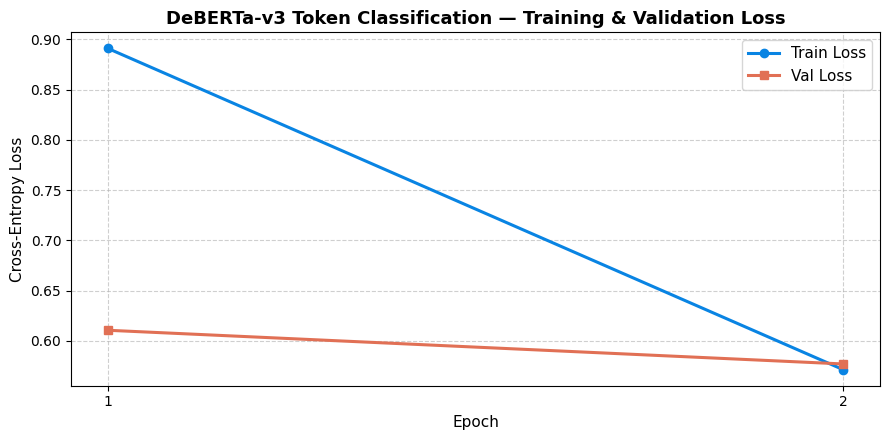

✅ Loss curve plot saved to: outputs/loss_curve.png


In [ ]:
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], marker='o', color='#0984e3', linewidth=2.2, label='Train Loss')
plt.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], marker='s', color='#e17055', linewidth=2.2, label='Val Loss')
plt.title("DeBERTa-v3 Token Classification — Training & Validation Loss", fontsize=13, fontweight='bold')
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Cross-Entropy Loss", fontsize=11)
plt.xticks(range(1, len(history["train_loss"]) + 1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(CFG["output_dir"], "loss_curve.png"), dpi=200)
plt.show()
print(f"✅ Loss curve plot saved to: {CFG['output_dir']}loss_curve.png")

## 9. Inference & Discourse Span Extraction (Post-Processing)

Converts predicted subword token logits into word-level predictions, groups contiguous BIO tags into full discourse spans, applies minimum span length filtering to eliminate spurious noise, and computes confidence scores.

In [ ]:
def predict_essay_spans(
    text: str,
    model: nn.Module,
    tokenizer,
    device: torch.device,
    max_len: int = 1024,
    o_threshold: float = 0.50,
    min_len_dict: Optional[Dict[str, int]] = None
) -> List[Dict[str, Any]]:
    """
    Takes raw essay text and extracts predicted discourse spans with classes,
    word indices, text snippets, and confidence scores.
    """
    if min_len_dict is None:
        min_len_dict = {
            "Lead": 3, "Position": 3, "Claim": 3,
            "Counterclaim": 3, "Rebuttal": 3,
            "Evidence": 5, "Concluding Statement": 4
        }

    words = text.split()
    if not words:
        return []

    tokenized = tokenizer(
        words,
        is_split_into_words=True,
        truncation=True,
        max_length=max_len,
        padding="max_length",
        return_tensors="pt"
    )

    word_ids = tokenized.word_ids()
    input_ids = tokenized["input_ids"].to(device)
    attention_mask = tokenized["attention_mask"].to(device)

    model.eval()
    with torch.no_grad():
        with torch.amp.autocast(device_type="cuda" if device.type == "cuda" else "cpu", enabled=device.type == "cuda"):
            outputs = model(input_ids, attention_mask)
            logits = outputs.logits[0]  # [seq_len, num_labels]
            probs = torch.softmax(logits.float(), dim=-1).cpu().numpy()

    # Subword -> Word mapping
    word_pred_labels = ["O"] * len(words)
    word_confs = [1.0] * len(words)
    seen_words = set()

    for token_idx, w_id in enumerate(word_ids):
        if w_id is None or w_id in seen_words:
            continue
        if w_id < len(words):
            p = probs[token_idx]
            if p[0] < o_threshold:
                best_idx = int(np.argmax(p[1:])) + 1
            else:
                best_idx = int(np.argmax(p))
            word_pred_labels[w_id] = ID2LABEL[best_idx]
            word_confs[w_id] = float(p[best_idx])
        seen_words.add(w_id)

    # Group BIO tags -> Spans
    spans = []
    current_type = None
    current_start = None
    current_confs = []

    def add_span(ctype, cstart, cend, conf_list):
        span_len = cend - cstart + 1
        if span_len >= min_len_dict.get(ctype, 1):
            span_text = " ".join(words[cstart:cend+1])
            mean_conf = float(np.mean(conf_list)) if conf_list else 1.0
            spans.append({
                "type": ctype,
                "start_word": cstart,
                "end_word": cend,
                "text": span_text,
                "confidence": mean_conf,
                "predictionstring": " ".join(str(x) for x in range(cstart, cend + 1))
            })

    for i, (lbl, conf) in enumerate(zip(word_pred_labels, word_confs)):
        if lbl.startswith("B-"):
            if current_type is not None:
                add_span(current_type, current_start, i - 1, current_confs)
            current_type = lbl[2:]
            current_start = i
            current_confs = [conf]
        elif lbl.startswith("I-"):
            tag_type = lbl[2:]
            if current_type == tag_type:
                current_confs.append(conf)
            else:
                if current_type is not None:
                    add_span(current_type, current_start, i - 1, current_confs)
                current_type = tag_type
                current_start = i
                current_confs = [conf]
        else: # "O"
            if current_type is not None:
                add_span(current_type, current_start, i - 1, current_confs)
            current_type = None
            current_start = None
            current_confs = []

    if current_type is not None:
        add_span(current_type, current_start, len(words) - 1, current_confs)

    return spans

# Load saved best checkpoint weights
if os.path.exists(checkpoint_path):
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    print(f"⭐ Loaded best model weights from: {checkpoint_path}")

# Test inference on a real validation essay
test_eid = val_ids[0]
test_essay = get_essay_text(test_eid, TXT_DIR)

predicted_spans = predict_essay_spans(
    test_essay,
    model,
    tokenizer,
    device,
    max_len=CFG["max_len"],
    o_threshold=float(CFG["o_threshold"])
)

print(f"\n=== PREDICTED DISCOURSE SPANS (Essay: {test_eid}, {len(predicted_spans)} spans) ===\n")
for sp in predicted_spans:
    short_txt = (sp["text"][:70] + "...") if len(sp["text"]) > 70 else sp["text"]
    conf_pct = sp["confidence"] * 100
    print(f"🏷️ [{sp['type']:<20}] (Words {sp['start_word']:>3}-{sp['end_word']:>3} | Conf: {conf_pct:>5.1f}%): \"{short_txt}\"")

⭐ Loaded best model weights from: outputs/model_weights.pt

=== 🎯 PREDICTED DISCOURSE SPANS (Essay: E805EA83734A, 10 spans) ===

🏷️ [Lead                ] (Words   3- 35 | Conf:  86.5%): "The electoral collage system has worked for many years however, citize..."
🏷️ [Claim               ] (Words  36- 39 | Conf:  57.2%): "is unfair to voters,"
🏷️ [Lead                ] (Words  40- 43 | Conf:  53.2%): "outdated, and the disaster"
🏷️ [Lead                ] (Words  45- 51 | Conf:  54.6%): "is a perfect example going against it."
🏷️ [Position            ] (Words  52- 73 | Conf:  88.9%): "Popular vote should be used in our modern society for a fair and clean..."
🏷️ [Claim               ] (Words  74- 94 | Conf:  81.5%): "The electoral collage voting system is an uncanny way for citizens to ..."
🏷️ [Evidence            ] (Words  95-201 | Conf:  87.9%): "They are voting for electors, not actual canidates. It isn't a straigh..."
🏷️ [Claim               ] (Words 202-211 | Conf:  91.4%): "The elect

## 10. Interactive HTML Color Visualizer (Highlighter)

Provides an interactive, color-coded visualizer comparing **Ground Truth** annotations with **Model Predictions** side-by-side on any student essay.

In [ ]:
# Color Palette for Discourse Elements
COLORS = {
    "Lead": "#ffeaa7",                 # Yellowish
    "Position": "#55efc4",             # Soft Green
    "Claim": "#81ecec",                # Cyan / Turquoise
    "Counterclaim": "#fab1a0",         # Coral / Orange
    "Rebuttal": "#ff7675",             # Soft Red / Pink
    "Evidence": "#74b9ff",             # Sky Blue
    "Concluding Statement": "#a29bfe"  # Soft Purple
}

def render_discourse_html(text: str, spans: List[Dict[str, Any]], title: str = "Discourse Elements Visualization") -> str:
    words = text.split()
    word_meta = [None] * len(words)

    for sp in spans:
        dtype = sp["type"]
        s_idx = sp["start_word"]
        e_idx = sp["end_word"]
        for i in range(s_idx, min(e_idx + 1, len(words))):
            word_meta[i] = dtype

    # 1. Color Legend
    legend_items = []
    for dt, col in COLORS.items():
        legend_items.append(
            f"<span style='background-color: {col}; color: #2d3436; padding: 4px 9px; margin: 3px; border-radius: 6px; font-weight: bold; font-size: 12px; display: inline-block; box-shadow: 0 1px 3px rgba(0,0,0,0.1);'>{dt}</span>"
        )
    legend_html = "".join(legend_items)

    # 2. Highlighted Text Body
    html_chunks = [
        f"<div style='border: 2px solid #dfe6e9; border-radius: 12px; padding: 20px; background: #ffffff; margin-top: 10px; font-family: Segoe UI, -apple-system, BlinkMacSystemFont, Roboto, sans-serif;'>",
        f"<h3 style='margin-top: 0; color: #2d3436; font-size: 18px;'>📊 {title}</h3>",
        f"<div style='margin-bottom: 18px; padding-bottom: 12px; border-bottom: 1px solid #edf2f7;'>{legend_html}</div>",
        "<div style='line-height: 2.5; font-size: 16px; color: #2d3436;'>"
    ]

    cur_type = None
    for w, dt in zip(words, word_meta):
        if dt != cur_type:
            if cur_type is not None:
                html_chunks.append(f" <b style='font-size: 11px; color: #2d3436; background: rgba(255,255,255,0.85); padding: 2px 6px; border-radius: 4px; border: 1px solid rgba(0,0,0,0.1);'>[{cur_type}]</b></span> ")
            if dt is not None:
                color = COLORS.get(dt, "#dfe6e9")
                html_chunks.append(f"<span style='background-color: {color}; padding: 4px 8px; border-radius: 6px; margin: 0 2px; box-shadow: 0 1px 2px rgba(0,0,0,0.08);'>")
            cur_type = dt
        html_chunks.append(w + " ")

    if cur_type is not None:
        html_chunks.append(f" <b style='font-size: 11px; color: #2d3436; background: rgba(255,255,255,0.85); padding: 2px 6px; border-radius: 4px; border: 1px solid rgba(0,0,0,0.1);'>[{cur_type}]</b></span>")

    html_chunks.append("</div></div>")
    return "".join(html_chunks)

# Visualization 1: Ground Truth Spans
sample_eid = val_ids[0]
sample_txt = get_essay_text(sample_eid, TXT_DIR)
gt_rows = df[df['id'] == sample_eid]
gt_spans_list = []
for _, row in gt_rows.iterrows():
    dtype = row["discourse_type"]
    w_idxs = [int(x) for x in str(row["predictionstring"]).split()]
    if w_idxs:
        span_txt = " ".join(sample_txt.split()[w_idxs[0]:w_idxs[-1]+1])
        gt_spans_list.append({
            "type": dtype,
            "start_word": w_idxs[0],
            "end_word": w_idxs[-1],
            "text": span_txt,
            "confidence": 1.0,
            "predictionstring": str(row["predictionstring"])
        })

gt_view = render_discourse_html(sample_txt, gt_spans_list, title=f"Ground Truth Annotations (Essay ID: {sample_eid})")
display(HTML(gt_view))

# Visualization 2: Model Predicted Spans
pred_view = render_discourse_html(sample_txt, predicted_spans, title=f"Model Predictions (Essay ID: {sample_eid})")
display(HTML(pred_view))

## 11. Official Macro-F1 Metric Evaluation (Validation Set)

Evaluates the entire validation set using the official **Span Overlap ($IoU \ge 0.5$) Macro-F1** competition metric, providing:
1. **Per-Class Precision, Recall, and F1-Score** across all 7 discourse classes.
2. **Official Overall Macro-F1 Score** (unweighted arithmetic mean of the 7 class F1 scores).
3. **Per-Class F1 Performance Bar Chart**.

🎯 Evaluating validation set spans with official competition metric...
📊 Evaluating 200 validation essays (out of 2,340 total)...

⭐ Loaded model checkpoint from: outputs/model_weights.pt


Evaluating Validation Spans:   0%|          | 0/200 [00:00<?, ?it/s]


🏆 OFFICIAL COMPETITION MACRO-F1 SCORE: 0.6069

📊 Detailed Performance Metrics by Discourse Class:


,Discourse Type,Precision,Recall,F1-Score,TP,FP,FN,Ground Truth Count,Pred Count
0,Lead,0.6114,0.8359,0.7063,107,68,21,128,175
1,Position,0.6316,0.7273,0.6761,144,84,54,198,228
2,Claim,0.5000,0.5675,0.5316,370,370,282,652,740
3,Counterclaim,0.5315,0.6782,0.5960,59,52,28,87,111
4,Rebuttal,0.3789,0.5000,0.4311,36,59,36,72,95
5,Evidence,0.5241,0.6426,0.5773,392,356,218,610,748
6,Concluding Statement,0.6438,0.8427,0.7299,150,83,28,178,233


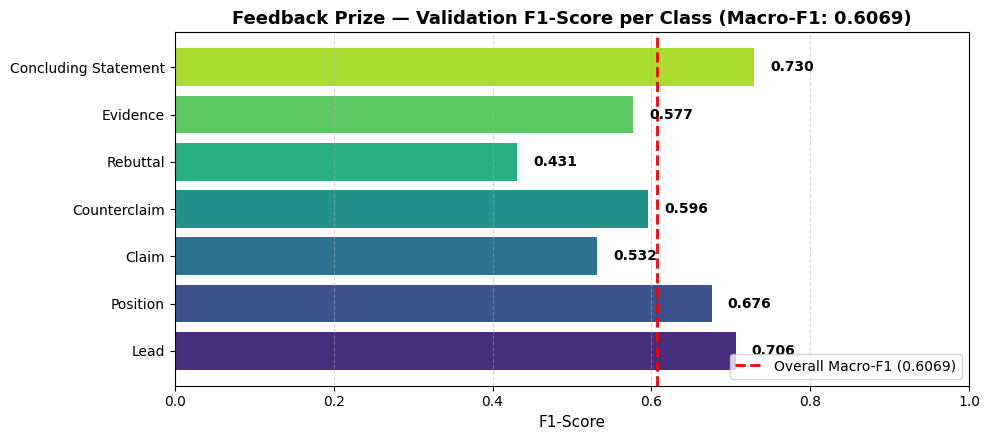

In [ ]:
# Compute official Feedback Prize Macro-F1 (Span Overlap IoU >= 0.5) metric
print(" Evaluating validation set spans with official competition metric...")

# Number of validation essays to evaluate (default: 200 for fast verification, or len(val_ids) for full set)
num_eval_essays = min(200, len(val_ids))
eval_val_ids = val_ids[:num_eval_essays]
print(f" Evaluating {len(eval_val_ids):,} validation essays (out of {len(val_ids):,} total)...\n")

# Ground Truth data for evaluated validation essays
gt_val_df = df[df["id"].isin(eval_val_ids)][["id", "discourse_type", "predictionstring"]].reset_index(drop=True)

# Load best model weights
if os.path.exists(checkpoint_path):
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    print(f"⭐ Loaded model checkpoint from: {checkpoint_path}")

# Generate all validation predictions
pred_rows = []
for essay_id in tqdm(eval_val_ids, desc="Evaluating Validation Spans"):
    essay_text = get_essay_text(essay_id, TXT_DIR)
    spans = predict_essay_spans(
        text=essay_text,
        model=model,
        tokenizer=tokenizer,
        device=device,
        max_len=CFG["max_len"],
        o_threshold=float(CFG["o_threshold"])
    )
    for sp in spans:
        pred_rows.append({
            "id": essay_id,
            "discourse_type": sp["type"],
            "predictionstring": sp["predictionstring"]
        })

pred_val_df = pd.DataFrame(pred_rows)

# Compute official competition Macro-F1 metric
macro_f1, detailed_df = score_feedback_comp_detailed(pred_val_df, gt_val_df, overlap_threshold=0.5)

print("\n" + "=" * 85)
print(f" OFFICIAL COMPETITION MACRO-F1 SCORE: {macro_f1:.4f}")
print("=" * 85 + "\n")

print(" Detailed Performance Metrics by Discourse Class:")
display(detailed_df)

# Plot F1-Score per Class Bar Plot
plt.figure(figsize=(10, 4.5))
palette = sns.color_palette("viridis", len(detailed_df))
bars = plt.barh(detailed_df["Discourse Type"], detailed_df["F1-Score"], color=palette)
plt.title(f"Feedback Prize — Validation F1-Score per Class (Macro-F1: {macro_f1:.4f})", fontsize=13, fontweight='bold')
plt.xlabel("F1-Score", fontsize=11)
plt.xlim(0, 1.0)
plt.axvline(x=macro_f1, color='red', linestyle='--', linewidth=2, label=f'Overall Macro-F1 ({macro_f1:.4f})')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.02, bar.get_y() + bar.get_height()/2, f"{w:.3f}", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## 12. In-Depth Error Analysis & Failure Modes

### Primary Error Categories:
1. **Span Boundary Mismatch**:
   - The boundary between `Claim` and `Evidence` is often nuanced; students frequently blend arguments without clear punctuation, causing spans to start or end slightly earlier/later.
2. **Minority Class Confusion (Class Imbalance: Counterclaim vs. Rebuttal)**:
   - `Counterclaim` (4.0%) and `Rebuttal` (3.0%) are minority classes in the dataset and share similar lexical discourse markers (*"However", "On the other hand", "Some people argue"*).
3. **Discourse Marker Ambiguity**:
   - Introductory and concluding transitions in essays are occasionally classified as Claims when an author restates their core thesis.

In [ ]:
# Automatic error case analysis on validation essays
print(" Performing automatic error analysis on validation essays...")

error_cases = []
for v_id in val_ids[:10]:
    v_text = get_essay_text(v_id, TXT_DIR)
    v_gt_rows = df[df['id'] == v_id]
    v_gt_spans = []
    for _, row in v_gt_rows.iterrows():
        w_idxs = [int(x) for x in str(row["predictionstring"]).split()]
        if w_idxs:
            v_gt_spans.append((row["discourse_type"], w_idxs[0], w_idxs[-1]))

    v_preds = predict_essay_spans(v_text, model, tokenizer, device, max_len=CFG["max_len"])
    v_pred_spans = [(p["type"], p["start_word"], p["end_word"]) for p in v_preds]

    # Identify missed / unaligned spans (IoU < 0.5)
    for gt_t, gt_s, gt_e in v_gt_spans:
        matched = False
        for pr_t, pr_s, pr_e in v_pred_spans:
            if gt_t == pr_t:
                iou = compute_overlap_ratio((pr_s, pr_e), (gt_s, gt_e))
                if iou >= 0.5:
                    matched = True
                    break
        if not matched:
            error_cases.append({
                "essay_id": v_id,
                "missed_type": gt_t,
                "span_words": f"{gt_s}-{gt_e}",
                "text_snippet": " ".join(v_text.split()[gt_s:gt_e+1])[:90] + "..."
            })

error_df = pd.DataFrame(error_cases)
print(f"\n⚠️ Found {len(error_df)} challenging / mismatched spans across the first 10 validation essays:")
if not error_df.empty:
    display(error_df.head(6))


🔍 Performing automatic error analysis on validation essays...

⚠️ Found 33 challenging / mismatched spans across the first 10 validation essays:


,essay_id,missed_type,span_words,text_snippet
0,E805EA83734A,Evidence,74-102,The electoral collage voting system is an unca...
1,E805EA83734A,Claim,103-151,It isn't a straight forward vote- electors are...
2,E805EA83734A,Evidence,152-201,"There is a winner-take-all system, which sugge..."
3,E805EA83734A,Claim,202-228,The electoral collage system of voting is outd...
4,E805EA83734A,Evidence,229-278,Citizens through out the country are looking f...
5,E805EA83734A,Evidence,279-292,The 2000 disaster is a great example for us to...
